# BigMart Sales Prediction - Part 3: Final predictions and submission file

Now I train my chosen models on **all** the training data and predict the test set.

Final model = 70% (price x store rate) + 30% Random Forest.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor

train = pd.read_csv('train_clean.csv')
test = pd.read_csv('test_clean.csv')
sample = pd.read_csv('sample_submission.csv')

print('train:', train.shape)
print('test: ', test.shape)
print('sample submission:', sample.shape)

train: (8523, 18)
test:  (5681, 16)
sample submission: (5681, 3)


## Part A: price x store rate

In [2]:
units = train['Item_Outlet_Sales'] / train['Base_Price']
store_rate = units.groupby(train['Outlet_Identifier']).mean()

print('units per store (this is the whole model):')
print(store_rate.round(2).sort_values().to_string())

units per store (this is the whole model):
Outlet_Identifier
OUT010     2.38
OUT019     2.45
OUT018    13.85
OUT045    15.57
OUT013    16.00
OUT046    16.19
OUT049    16.62
OUT017    16.66
OUT035    16.97
OUT027    26.60


In [3]:
rule_prediction = test['Base_Price'].values * test['Outlet_Identifier'].map(store_rate).values

print('any missing?', np.isnan(rule_prediction).sum())
print(rule_prediction[:5].round(1))

any missing? 0
[1759.7 1453.4  572.7 2551.7 6199.4]


## Part B: Random Forest

In [4]:
# same columns as in Part 2
word_columns = ['Item_Fat_Content', 'Item_Type', 'Outlet_Identifier', 'Outlet_Size',
                'Outlet_Location_Type', 'Outlet_Type', 'Item_Category']
number_columns = ['Base_Price', 'Item_MRP', 'Item_Weight', 'Item_Visibility',
                  'Outlet_Age', 'Price_per_Weight']

# make dummies on train and test together so both have the exact same columns
all_rows = pd.concat([train[word_columns + number_columns], test[word_columns + number_columns]])
all_rows = pd.get_dummies(all_rows, columns=word_columns)

X_train = all_rows.iloc[:len(train)]
X_test = all_rows.iloc[len(train):]

print(X_train.shape, X_test.shape)

(8523, 48) (5681, 48)


In [5]:
forest = RandomForestRegressor(n_estimators=200, max_depth=6, min_samples_leaf=30,
                               random_state=42, n_jobs=-1)
forest.fit(X_train, train['Item_Outlet_Sales'])

forest_prediction = forest.predict(X_test)
print(forest_prediction[:5].round(1))

[1635.1 1373.1  611.6 2481.  6265.7]


## Blend them and save

In [6]:
final_prediction = 0.7 * rule_prediction + 0.3 * forest_prediction

# sales can't be negative
final_prediction = np.clip(final_prediction, 0, None)

submission = pd.DataFrame()
submission['Item_Identifier'] = test['Item_Identifier']
submission['Outlet_Identifier'] = test['Outlet_Identifier']
submission['Item_Outlet_Sales'] = final_prediction

submission.to_csv('submission.csv', index=False)
submission.head()

,Item_Identifier,Outlet_Identifier,Item_Outlet_Sales
0,FDW58,OUT049,1722.308836
1,FDW14,OUT017,1429.277886
2,NCN55,OUT010,584.344195
3,FDQ58,OUT017,2530.485402
4,FDY38,OUT027,6219.257782


## Checking the file before I submit it

In [7]:
# same rows in the same order as the sample file?
print('same shape as sample:', submission.shape == sample.shape)
print('same column names:   ', list(submission.columns) == list(sample.columns))
print('same item ids, in order:  ', (submission['Item_Identifier'] == sample['Item_Identifier']).all())
print('same outlet ids, in order:', (submission['Outlet_Identifier'] == sample['Outlet_Identifier']).all())
print('missing values:', submission['Item_Outlet_Sales'].isnull().sum())
print('smallest / largest prediction:', submission['Item_Outlet_Sales'].min().round(1), '/', submission['Item_Outlet_Sales'].max().round(1))

same shape as sample: True
same column names:    True
same item ids, in order:   True
same outlet ids, in order: True
missing values: 0
smallest / largest prediction: 80.3 / 6817.3


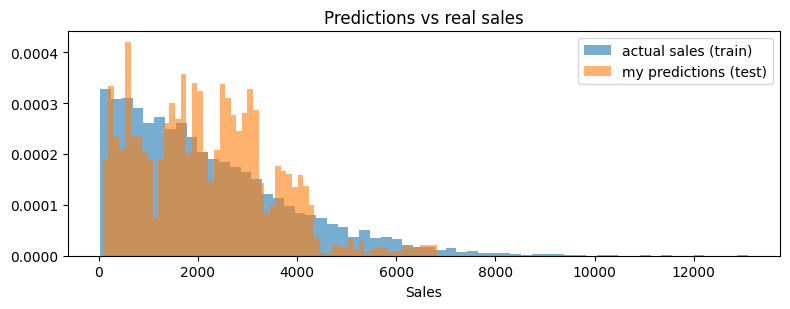

In [8]:
# do the predictions look like the real sales?
plt.figure(figsize=(8, 3.2))
plt.hist(train['Item_Outlet_Sales'], bins=60, alpha=0.6, density=True, label='actual sales (train)')
plt.hist(final_prediction, bins=60, alpha=0.6, density=True, label='my predictions (test)')
plt.xlabel('Sales')
plt.legend()
plt.title('Predictions vs real sales')
plt.tight_layout()
plt.show()

## Summary

- **Cleaning:** fixed the fat-content labels, filled missing weights from the same product, filled the three missing store sizes with `Small`, and replaced zero visibility.
- **Main finding:** sales = hidden price x whole number of units. Recovering the price and then using one "units" number per store gave the best CV score.
- **Models tried:** average, store average, Linear Regression, Decision Tree, Random Forest, and my price x store rule. The simple rule won.
- **What drives sales:** mainly the **store** (grocery stores sell about 2 units, Type3 about 27) and the **price**. Weight, visibility and fat content barely matter.
- **Final answer:** 70% rule + 30% Random Forest, saved as `submission.csv`.